# Lab 1: Oracles, the Deutsch Algorithm and the Deutsch-Jozsa Algorithm
*Adapted from the IBM Quantum lab "Oracles and the Deutsch-Jozsa Algorithm".*

**Duration: 90 minutes.** The theory was covered in the lecture; in this lab you build and run the circuits.

| Part |
|---|
| Installation |
| Part 1) Classical oracles |
| Part 2) The Deutsch algorithm (1 input bit) |
| Part 3) The Deutsch-Jozsa problem |
| Part 4) The Deutsch-Jozsa algorithm ($n$ input bits) |
| Problems 1–10 |

**How to use this notebook**
- **Exercises** are highlighted in green boxes. Write your code between the `### FILL YOUR CODE IN HERE` markers in the cell below each box.
- **Check** cells test your code. If they print a success message you can move on; if they raise an error, read the message.
- **Q** — answer the question in the cell below it.
- **Optional** — do these only if you are ahead of the schedule.

## Installation

Run this cell first to check your Python version.

In [1]:
import sys

recommended = (3, 10)
current = sys.version_info[:2]

if current < recommended:
    print(f"You are using Python {current[0]}.{current[1]}. Python {recommended[0]}.{recommended[1]} or later is recommended.")
else:
    print(f"Python {current[0]}.{current[1]} — looks good!")

Python 3.13 — looks good!


Next, run the cell below to install and upgrade the required packages. If the upgrade process causes dependency conflicts with packages already installed in your local environment, __create a new Python environment__ (Python 3.12 recommended) and continue the lab there.

For guidance on setting up a clean environment and installing Qiskit, refer to the IBM Quantum documentation: https://quantum.cloud.ibm.com/docs/guides/install-qiskit

In [2]:
# Dependencies are already installed in the project .venv.
# Verified with Qiskit 2.5.2, Qiskit Aer 0.17.2, and Matplotlib 3.11.2.
# Uncomment the following line only when setting up a new environment:
# %pip install --upgrade 'qiskit[visualization]>=2.5.0' qiskit-aer matplotlib

Once you have installed and upgraded the libraries, please restart the Python kernel and rerun the notebook starting from the Import Libraries cell below.

In [3]:
# Import Libraries
import random
import numpy as np
from IPython.display import display

# Importing standard Qiskit libraries
import qiskit
import qiskit_aer
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.quantum_info import Statevector, Operator
from qiskit.visualization import plot_bloch_multivector, plot_histogram
from matplotlib import pyplot as plt

sim = AerSimulator(seed_simulator=2026)

def run(qc, shots=1024):
    """Simulate a circuit and return the measurement counts."""
    return sim.run(transpile(qc, sim), shots=shots).result().get_counts()

print(f"Qiskit version: {qiskit.__version__}")
print(f"Qiskit Aer version: {qiskit_aer.__version__}")

Qiskit version: 2.5.2
Qiskit Aer version: 0.17.2


Run the next cell. It defines the check functions — you do not need to read it.

In [4]:
# Check functions (you do not need to read this cell)

def _state(qc):
    return Statevector(qc.remove_final_measurements(inplace=False))

def _counts(qc, what):
    assert qc.count_ops().get('measure', 0) > 0, f"{what} has no measurement - did you forget qc.measure(...)?"
    return run(qc)

def check_classical_solver(solver):
    worst = {}
    for n in range(1, 7):
        for seed in range(300):
            f = ClassicalOracle(n, seed)
            truth = "constant" if len(set(f._table)) == 1 else "balanced"
            answer = solver(f)
            assert answer == truth, f"n = {n}, seed = {seed}: you answered {answer!r}, but the function is {truth!r}."
            assert f.queries <= 2**(n - 1) + 1, (f"n = {n}, seed = {seed}: you used {f.queries} queries. "
                                                 "You can always decide with fewer - when can you stop?")
            worst[n] = max(worst.get(n, 0), f.queries)
    print("classical_solver is always correct for n = 1 ... 6")
    print("   most queries you needed:", ", ".join(f"n={n}: {q}" for n, q in worst.items()))

def check_deutsch_oracle(make_oracle):
    expected = {0: [0, 0], 1: [1, 1], 2: [0, 1], 3: [1, 0]}
    for case, table in expected.items():
        U = Operator(make_oracle(case)).data
        for x in (0, 1):
            for y in (0, 1):
                out = ((y ^ table[x]) << 1) | x      # basis index of |q1 q0> = |y XOR f(x), x>
                assert np.isclose(abs(U[out, (y << 1) | x]), 1), (
                    f"case {case}: U_f |x={x}>|y={y}> should give |x={x}>|y={y ^ table[x]}>")
    print("deutsch_oracle is correct for all four functions")

def check_deutsch_circuit(make_circuit):
    for case in range(4):
        counts = _counts(make_circuit(deutsch_oracle(case)), "deutsch_circuit")
        expected = '0' if case < 2 else '1'
        kind = 'constant' if case < 2 else 'balanced'
        assert counts == {expected: 1024}, f"f{case} is {kind}: expected {{'{expected}': 1024}}, got {counts}"
        print(f"   f{case} ({kind}): {counts}")
    print("deutsch_circuit is correct: one query tells constant (0) from balanced (1)")

def check_psi_0(psi_0, n):
    assert _state(psi_0(n)).equiv(Statevector.from_label('-' + '0' * n)), \
        f"psi_0 should be |-> on q_{n} and |0> on q_0 ... q_{n-1}"
    print("psi_0 is correct")

def check_psi_1(psi_1, n):
    assert _state(psi_1(n)).equiv(Statevector.from_label('-' + '+' * n)), \
        f"psi_1 should be |-> on q_{n} and |+> on q_0 ... q_{n-1}"
    print("psi_1 is correct")

def check_psi_2(psi_2, oracle, n):
    expected = Statevector.from_label('-' + '+' * n).evolve(Operator(oracle))
    assert _state(psi_2(oracle, n)).equiv(expected), "psi_2 should be the oracle applied once to psi_1"
    print("psi_2 is correct")

def check_full_circuit(full_circuit, n):
    const = QuantumCircuit(n + 1, name="constant"); const.x(n)
    c = _counts(full_circuit(const.to_gate(), n), "full_circuit")
    assert c == {'0' * n: 1024}, f"for a constant oracle you should always measure {'0' * n}, got {c}"
    for i in range(n):                       # balanced f(x) = x_i: one test per input qubit
        bal = QuantumCircuit(n + 1, name=f"x{i}"); bal.cx(i, n)
        b = _counts(full_circuit(bal.to_gate(), n), "full_circuit")
        assert '0' * n not in b, (f"for the balanced oracle f(x) = x_{i} you measured {'0' * n}, so it looks "
                                  f"constant - are a Hadamard and a measurement applied to q_{i}? got {b}")
    print("full_circuit is correct")

## Oracles and query complexity
Many quantum algorithms revolve around the notion of so-called *oracles*. An oracle is a function that we can only use as a "black box": we can ask it questions (*queries*) but cannot look inside. We want to find out a property of this function. The *query complexity* is the minimum number of queries needed to determine that property.

In this lab the hidden function $f$ is guaranteed to be one of two kinds, and we must decide which:
- **constant** — returns the same value (all 0 or all 1) for every input
- **balanced** — returns 0 for exactly half of the inputs and 1 for the other half

We start with the simplest case, a function of one bit (the **Deutsch problem**), and then generalise to $n$ bits (the **Deutsch-Jozsa problem**). Each time we compare how many queries a classical and a quantum computer need.

## Part 1) Classical oracles
### 1.1 All functions of one bit
A function $f:\{0,1\}\to\{0,1\}$ has only four possibilities. Run the cell to print their truth tables.

In [5]:
one_bit_functions = {
    "f0": lambda x: 0,
    "f1": lambda x: 1,
    "f2": lambda x: x,
    "f3": lambda x: 1 - x,
}

print("f   | f(0) f(1)")
for name, f in one_bit_functions.items():
    print(f"{name}  |  {f(0)}    {f(1)}")

f   | f(0) f(1)
f0  |  0    0
f1  |  1    1
f2  |  0    1
f3  |  1    0


**Q1.** Which of $f_0, f_1, f_2, f_3$ are constant and which are balanced?
You query the black box once and get $f(0) = 0$. Which functions are still possible — can you already tell whether $f$ is constant or balanced? What if you got $f(0) = 1$?

**Answer:** $f_0$ and $f_1$ are constant; $f_2$ and $f_3$ are balanced.

If $f(0)=0$, either $f_0$ (constant) or $f_2$ (balanced) is possible. If $f(0)=1$, either $f_1$ (constant) or $f_3$ (balanced) is possible. Neither result alone determines the type. A second classical query, at $x=1$, is necessary to be certain.

### 1.2 A classical black box
`ClassicalOracle(n)` hides a random function of $n$ bits that is guaranteed to be constant or balanced. You can only call it as `f(x)`, where `x` is an integer from `0` to `2**n - 1`. It counts every call in `f.queries`. (Please don't peek at `f._table` — that would be opening the box!)

In [6]:
class ClassicalOracle:
    """Black box: you can call f(x) but not look inside. Counts every query."""
    def __init__(self, n, seed=None):
        rng = random.Random(seed)
        self.n, N = n, 2**n
        if rng.random() < 0.5:                          # constant
            self._table = [rng.randint(0, 1)] * N
        else:                                           # balanced
            ones = set(rng.sample(range(N), N // 2))
            self._table = [int(x in ones) for x in range(N)]
        self.queries = 0

    def __call__(self, x):
        self.queries += 1
        return self._table[x]

<div class="alert alert-block alert-success">

**Exercise 1: Write a classical solver**

Write <code>classical_solver(f)</code> that returns <code>'constant'</code> or <code>'balanced'</code>. It must <b>always be correct</b> and use as few queries as possible.

Hint: when can you stop early? How many equal answers in a row guarantee "constant"?

</div>

In [7]:
def classical_solver(f):
    """Classify a promised oracle using at most 2**(f.n - 1) + 1 queries."""
    first = f(0)
    # Query distinct inputs; stop immediately when both output values appear.
    for x in range(1, 2**(f.n - 1) + 1):
        if f(x) != first:
            return 'balanced'
    # More than half the inputs agree, ruling out a balanced function.
    return 'constant'

In [8]:
# Check
check_classical_solver(classical_solver)

classical_solver is always correct for n = 1 ... 6
   most queries you needed: n=1: 2, n=2: 3, n=3: 5, n=4: 9, n=5: 17, n=6: 33


### 1.3 How many queries for $n$ bits?
Run your solver on 2000 random oracles with $n = 6$ and look at how many queries it needed.

constant: min = 33, max = 33 queries
balanced: min = 2, max = 13 queries


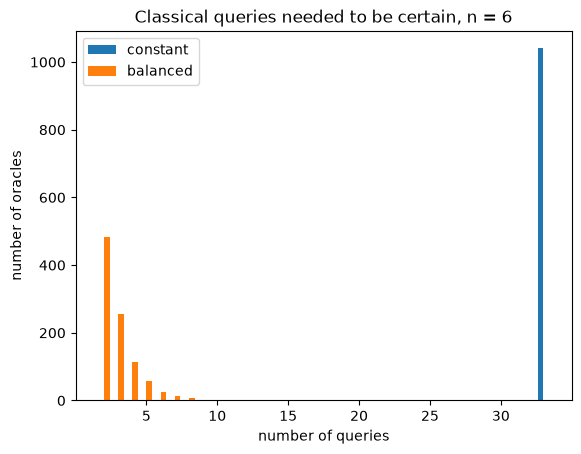

In [9]:
n = 6
queries = {"constant": [], "balanced": []}
for seed in range(2000):
    f = ClassicalOracle(n, seed)
    queries[classical_solver(f)].append(f.queries)

for kind, q in queries.items():
    print(f"{kind}: min = {min(q)}, max = {max(q)} queries")

plt.hist([queries["constant"], queries["balanced"]], bins=np.arange(1.5, 2**(n - 1) + 2.5),
         label=["constant", "balanced"])
plt.xlabel("number of queries")
plt.ylabel("number of oracles")
plt.title(f"Classical queries needed to be certain, n = {n}")
plt.legend()
plt.show()

**Q2.** For $n = 6$, what is the minimum and the maximum number of queries a classical computer needs to be *certain*? Which kind of function forces the maximum? What is the general formula for $n$ bits?

In [10]:
def query_bounds_N6():
    min_nr_inputs = 2
    max_nr_inputs = 33
    return [min_nr_inputs, max_nr_inputs]

print("Minimum and maximum queries for n=6:", query_bounds_N6())

Minimum and maximum queries for n=6: [2, 33]


**Answer to Q2:** For $n=6$, the best case needs **2 queries**: two different outputs prove that the function is balanced. The worst case needs **33 queries**. Every constant function forces the worst case, since 32 equal answers could still be half of a balanced truth table. A balanced function can also require 33 queries if the first 32 outputs agree and the next differs.

For $n\geq1$, the best case is 2 queries and the optimal deterministic worst-case bound is $2^{n-1}+1$. After only $2^{n-1}$ equal outputs, either a constant or a balanced completion remains possible; one more equal output rules out balanced. Thus the solver meets the lower bound without inspecting the hidden table.


**Optional — being *almost* sure.** If we accept a small chance of error, a classical computer can do much better: query $k$ random inputs and answer "constant" if all results are equal. For a balanced function this is wrong with probability about $1/2^{k-1}$ — only about 0.2% for $k = 10$. The advantage of the quantum algorithm in this lab is that it is **100% certain** after a single query.

## Part 2) The Deutsch algorithm
### 2.1 A quantum oracle for a 1-bit function
A quantum gate must be reversible, but $x \mapsto f(x)$ is not (for $f_0$ both inputs give 0, so we cannot recover $x$). The quantum oracle therefore keeps $x$ and adds the answer into an extra qubit $y$:
$$U_f\,|x\rangle|y\rangle = |x\rangle|y \oplus f(x)\rangle$$
where $\oplus$ is addition modulo 2 (XOR).

We put $x$ on qubit $q_0$ and $y$ on qubit $q_1$ — the same layout that the Deutsch-Jozsa oracle uses later (inputs on $q_0 \dots q_{n-1}$, output on $q_n$). In formulas we write $|x\rangle|y\rangle$; Qiskit writes the same state as $|q_1 q_0\rangle = |y\,x\rangle$.

| $f$ | $f(0)$ | $f(1)$ | circuit for $U_f$ |
|---|---|---|---|
| $f_0(x) = 0$ | 0 | 0 | do nothing |
| $f_1(x) = 1$ | 1 | 1 | X on $q_1$ |
| $f_2(x) = x$ | 0 | 1 | CNOT from $q_0$ to $q_1$ |
| $f_3(x) = \lnot x$ | 1 | 0 | **Exercise 2** |


<div class="alert alert-block alert-success">

**Exercise 2: Build the oracle for $f_3(x) = \lnot x$**

Complete <code>case == 3</code> in <code>deutsch_oracle</code> so that $U_{f_3}|x\rangle|y\rangle = |x\rangle|y \oplus \lnot x\rangle$.

Hint: $y \oplus \lnot x = (y \oplus x) \oplus 1$.

</div>

In [11]:
def deutsch_oracle(case):
    """Quantum oracle U_f for the 1-bit function f_case.
    q0 = x (input), q1 = y (output) -- the same layout as the Deutsch-Jozsa oracle.
    """
    qc = QuantumCircuit(2, name=f"U_f{case}")
    if case == 1:          # f1(x) = 1
        qc.x(1)
    elif case == 2:        # f2(x) = x
        qc.cx(0, 1)
    elif case == 3:        # f3(x) = NOT x: y XOR (1 XOR x)
        qc.cx(0, 1)
        qc.x(1)
    return qc              # case 0: f0(x) = 0 -> do nothing

deutsch_oracle is correct for all four functions


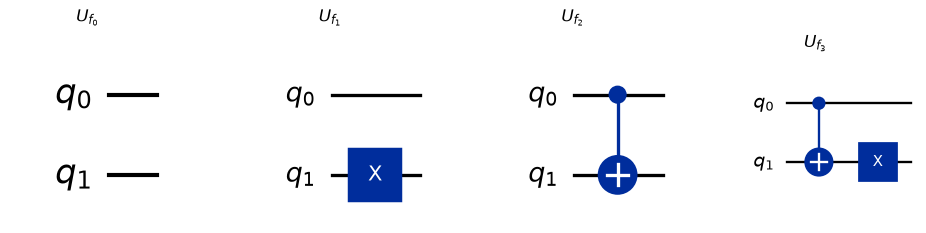

In [12]:
# Check
check_deutsch_oracle(deutsch_oracle)

fig, axes = plt.subplots(1, 4, figsize=(12, 2.5))
for case, ax in enumerate(axes):
    deutsch_oracle(case).draw(output='mpl', ax=ax)
    ax.set_title(f"$U_{{f_{case}}}$")
plt.show()

**Using the quantum oracle classically.** If we feed in a classical input $|x\rangle|0\rangle$, the oracle just writes $f(x)$ into $q_1$. Then it is no better than the classical black box: we still need **two runs** to learn $f(0)$ and $f(1)$.

In [13]:
def query_classically(oracle, x):
    """Feed the classical input |x>|0> into the oracle and measure y, which gives f(x)."""
    qc = QuantumCircuit(2, 1)
    if x == 1:
        qc.x(0)
    qc.compose(oracle, inplace=True)
    qc.measure(1, 0)
    counts = run(qc)
    return int(max(counts, key=counts.get))

for case in range(4):
    U = deutsch_oracle(case)
    print(f"f{case}: f(0) = {query_classically(U, 0)}, f(1) = {query_classically(U, 1)}")

f0: f(0) = 0, f(1) = 0
f1: f(0) = 1, f(1) = 1


f2: f(0) = 0, f(1) = 1
f3: f(0) = 1, f(1) = 0


**Optional.** Print the matrix of $U_{f_2}$. Every column contains a single 1: the oracle only permutes the basis states, which is why it is reversible. (Qiskit orders the basis as $|q_1 q_0\rangle$ = 00, 01, 10, 11.)

In [14]:
print(Operator(deutsch_oracle(2)).data.real.astype(int))

[[1 0 0 0]
 [0 0 0 1]
 [0 0 1 0]
 [0 1 0 0]]


### 2.2 Phase kickback
Now prepare the output qubit in $|-\rangle = \frac{1}{\sqrt2}(|0\rangle - |1\rangle)$. As shown in the lecture,
$$U_f\,|x\rangle|-\rangle = (-1)^{f(x)}\,|x\rangle|-\rangle$$
The value of $f(x)$ is "kicked back" as a phase onto the input qubit. If the input is the superposition $|+\rangle$:
$$U_f\,|+\rangle|-\rangle = \frac{1}{\sqrt2}\Big((-1)^{f(0)}|0\rangle + (-1)^{f(1)}|1\rangle\Big)|-\rangle = \begin{cases} \pm\,|+\rangle|-\rangle & f \text{ constant} \\ \pm\,|-\rangle|-\rangle & f \text{ balanced}\end{cases}$$
Run the cell to see both qubits after the oracle, for all four functions.

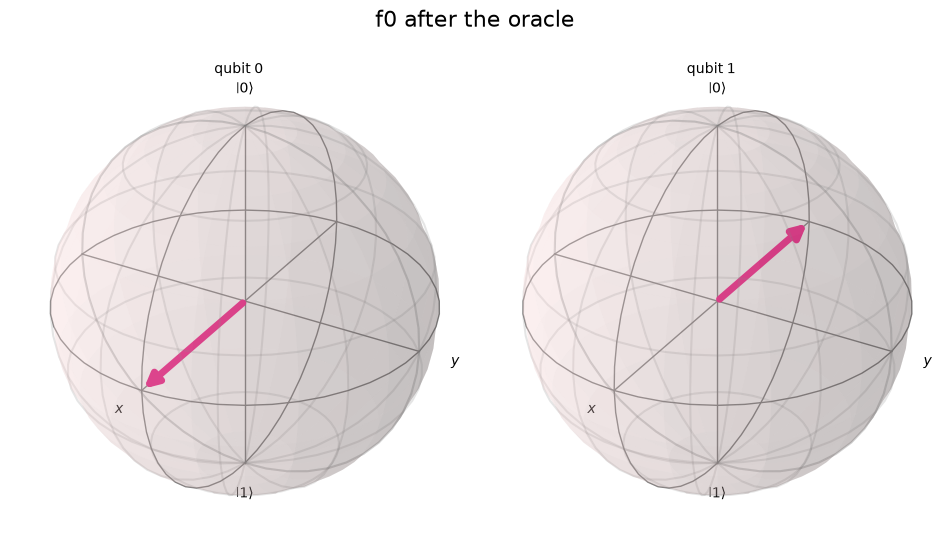

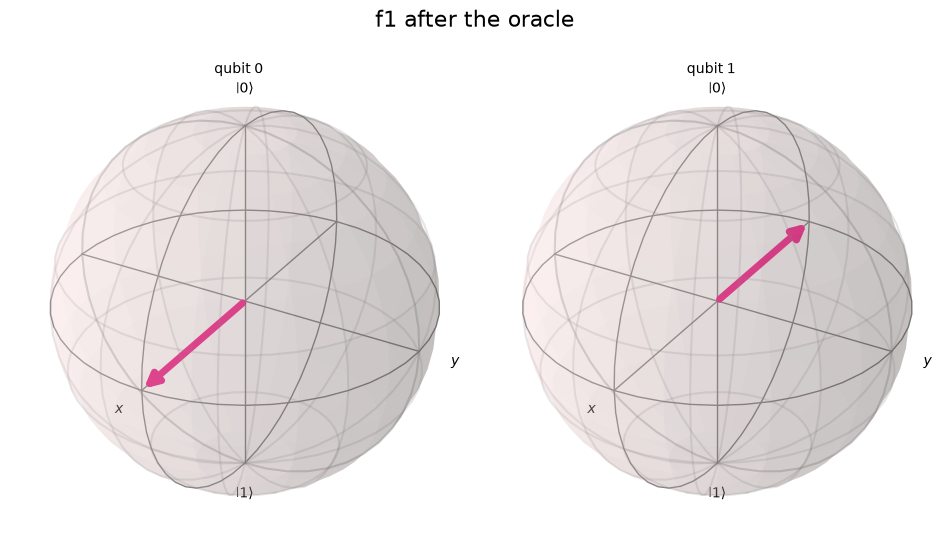

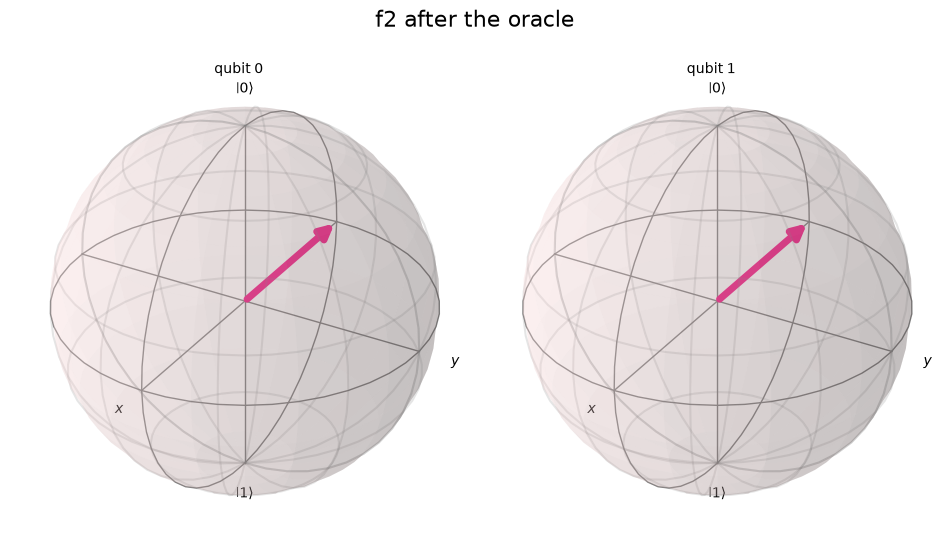

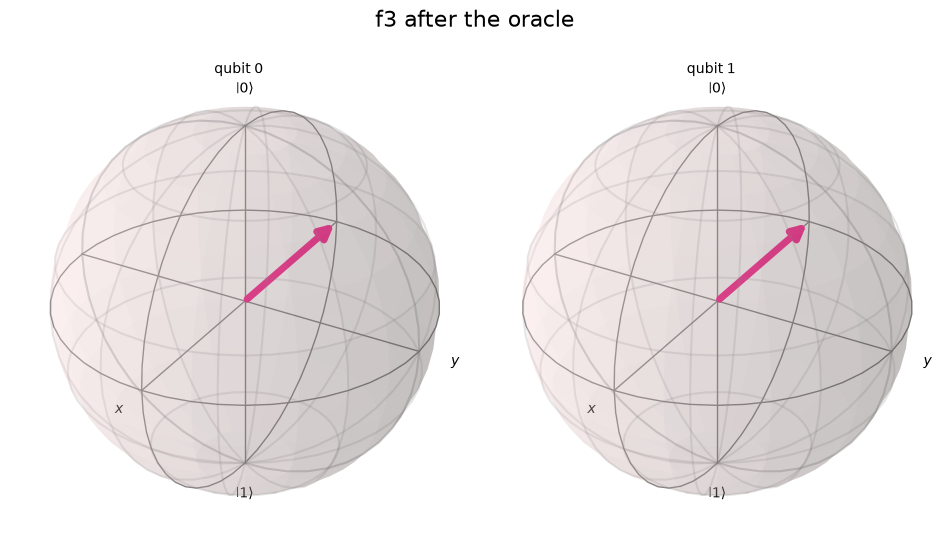

In [15]:
for case in range(4):
    kickback = QuantumCircuit(2)
    kickback.x(1)
    kickback.h(1)      # y = |->
    kickback.h(0)      # x = |+>
    kickback.compose(deutsch_oracle(case), inplace=True)
    display(plot_bloch_multivector(Statevector(kickback), title=f"f{case} after the oracle"))

**Q3.** Where does the Bloch vector of $q_0$ point for the constant functions, and for the balanced ones? Which single gate turns this difference into a measurement result of 0 or 1? Why do $f_0$ and $f_1$ look exactly the same?

**Answer:** For constant functions, the input qubit $q_0$ is $|+\rangle$, so its Bloch vector points along $+x$. For balanced functions it is $|-\rangle$, pointing along $-x$.

A Hadamard gate maps $|+\rangle$ to $|0\rangle$ and $|-\rangle$ to $|1\rangle$, making the two cases distinguishable by a computational-basis measurement. The states produced by $f_0$ and $f_1$ differ only by an overall factor of $-1$, a global phase that cannot affect measurements or Bloch vectors. The output qubit remains $|-\rangle$ in every case.

### 2.3 The full Deutsch circuit


<div class="alert alert-block alert-success">

**Exercise 3: Build the Deutsch circuit**

Complete <code>deutsch_circuit(oracle)</code>. The steps have the same names as in the Deutsch-Jozsa part later:

1. $|\psi_0\rangle = |-\rangle \otimes |0\rangle$ (Qiskit order $q_1 \otimes q_0$)
2. $|\psi_1\rangle = |-\rangle \otimes |+\rangle$
3. $|\psi_2\rangle = U_f\,|\psi_1\rangle$ — <b>one</b> query (already written for you)
4. Hadamard on $q_0$, then measure $q_0$ into classical bit 0

</div>

In [16]:
def deutsch_circuit(oracle):
    qc = QuantumCircuit(2, 1)

    # |psi_0> = |-> on q1 tensor |0> on q0 (Qiskit order).
    qc.x(1)
    qc.h(1)

    # |psi_1> = |-> tensor |+>.
    qc.h(0)

    # |psi_2>: apply the oracle exactly once.
    qc.compose(oracle, inplace=True)

    # Convert the relative phase into a computational-basis result.
    qc.h(0)
    qc.measure(0, 0)
    return qc

   f0 (constant): {'0': 1024}
   f1 (constant): {'0': 1024}
   f2 (balanced): {'1': 1024}


   f3 (balanced): {'1': 1024}
deutsch_circuit is correct: one query tells constant (0) from balanced (1)


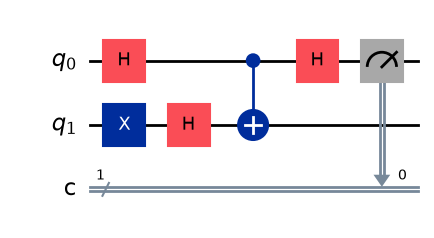

In [17]:
# Check
check_deutsch_circuit(deutsch_circuit)
deutsch_circuit(deutsch_oracle(2)).draw(output='mpl')

**One query, 100% certain:** measuring 0 means constant and 1 means balanced. Classically we needed 2 queries.

**Optional — mystery oracle.** `deutsch_mystery_oracle(seed)` hides one of the four oracles inside a gate. Query it **once** (`shots=1`) and decide whether it is constant or balanced. Try a few seeds.

In [18]:
def deutsch_mystery_oracle(seed):
    gate = deutsch_oracle(random.Random(seed).randint(0, 3)).to_gate()
    gate.name = "Mystery"
    return gate

# Each independently supplied mystery oracle is queried in exactly one shot.
for seed in (2026, 0, 1, 5):
    mystery = deutsch_mystery_oracle(seed)
    counts = run(deutsch_circuit(mystery), shots=1)
    outcome = next(iter(counts))
    kind = 'constant' if outcome == '0' else 'balanced'
    print(f"seed={seed}: {counts} -> {kind}")

seed=2026: {'0': 1} -> constant


seed=0: {'1': 1} -> balanced
seed=1: {'0': 1} -> constant


seed=5: {'1': 1} -> balanced


## Part 3) The Deutsch-Jozsa problem
Now the hidden Boolean function takes a string of $n$ bits:
$$f(\{x_0,x_1,\dots,x_{n-1}\}) \rightarrow 0 \textrm{ or } 1$$
and is again guaranteed to be either constant or balanced. The Deutsch problem from Part 2 is the case $n = 1$.

The Deutsch-Jozsa algorithm was the first example of a quantum algorithm that performs better than the best classical algorithm. It showed that there can be advantages to using a quantum computer as a computational tool for a specific problem.

The function below builds one of many hidden oracles: `problem` selects the oracle and `N` is the number of input bits.

In [19]:
def dj_problem_oracle(problem, N, to_gate=True):
    """U_f on N+1 qubits: inputs q_0 ... q_{N-1}, output q_N. Use N >= 2."""
    qc = QuantumCircuit(N+1)
    np.random.seed(problem)
    if np.random.randint(0, 2):
        qc.x(N)

    on_states = np.random.choice(range(2**N), 2**N // 2, replace=False)

    def add_cx(qc, bit_string):
        for qubit, bit in enumerate(reversed(bit_string)):
            if bit == "1":
                qc.x(qubit)
        return qc

    for state in on_states[:2**N//4]:
        qc = add_cx(qc, f"{state:0b}")
        qc.mcx(list(range(N)), N)
        qc = add_cx(qc, f"{state:0b}")
    if np.random.randint(0, 2):
        for state in on_states[2**N//4:]:
            qc = add_cx(qc, f"{state:0b}")
            qc.mcx(list(range(N)), N)
            qc = add_cx(qc, f"{state:0b}")
            qc.x(N)
    else:
        for state in on_states[2**N//4-1::-1]:
            qc = add_cx(qc, f"{state:0b}")
            qc.mcx(list(range(N)), N)
            qc = add_cx(qc, f"{state:0b}")

    if to_gate:
        return qc.to_gate()
    else:
        return qc

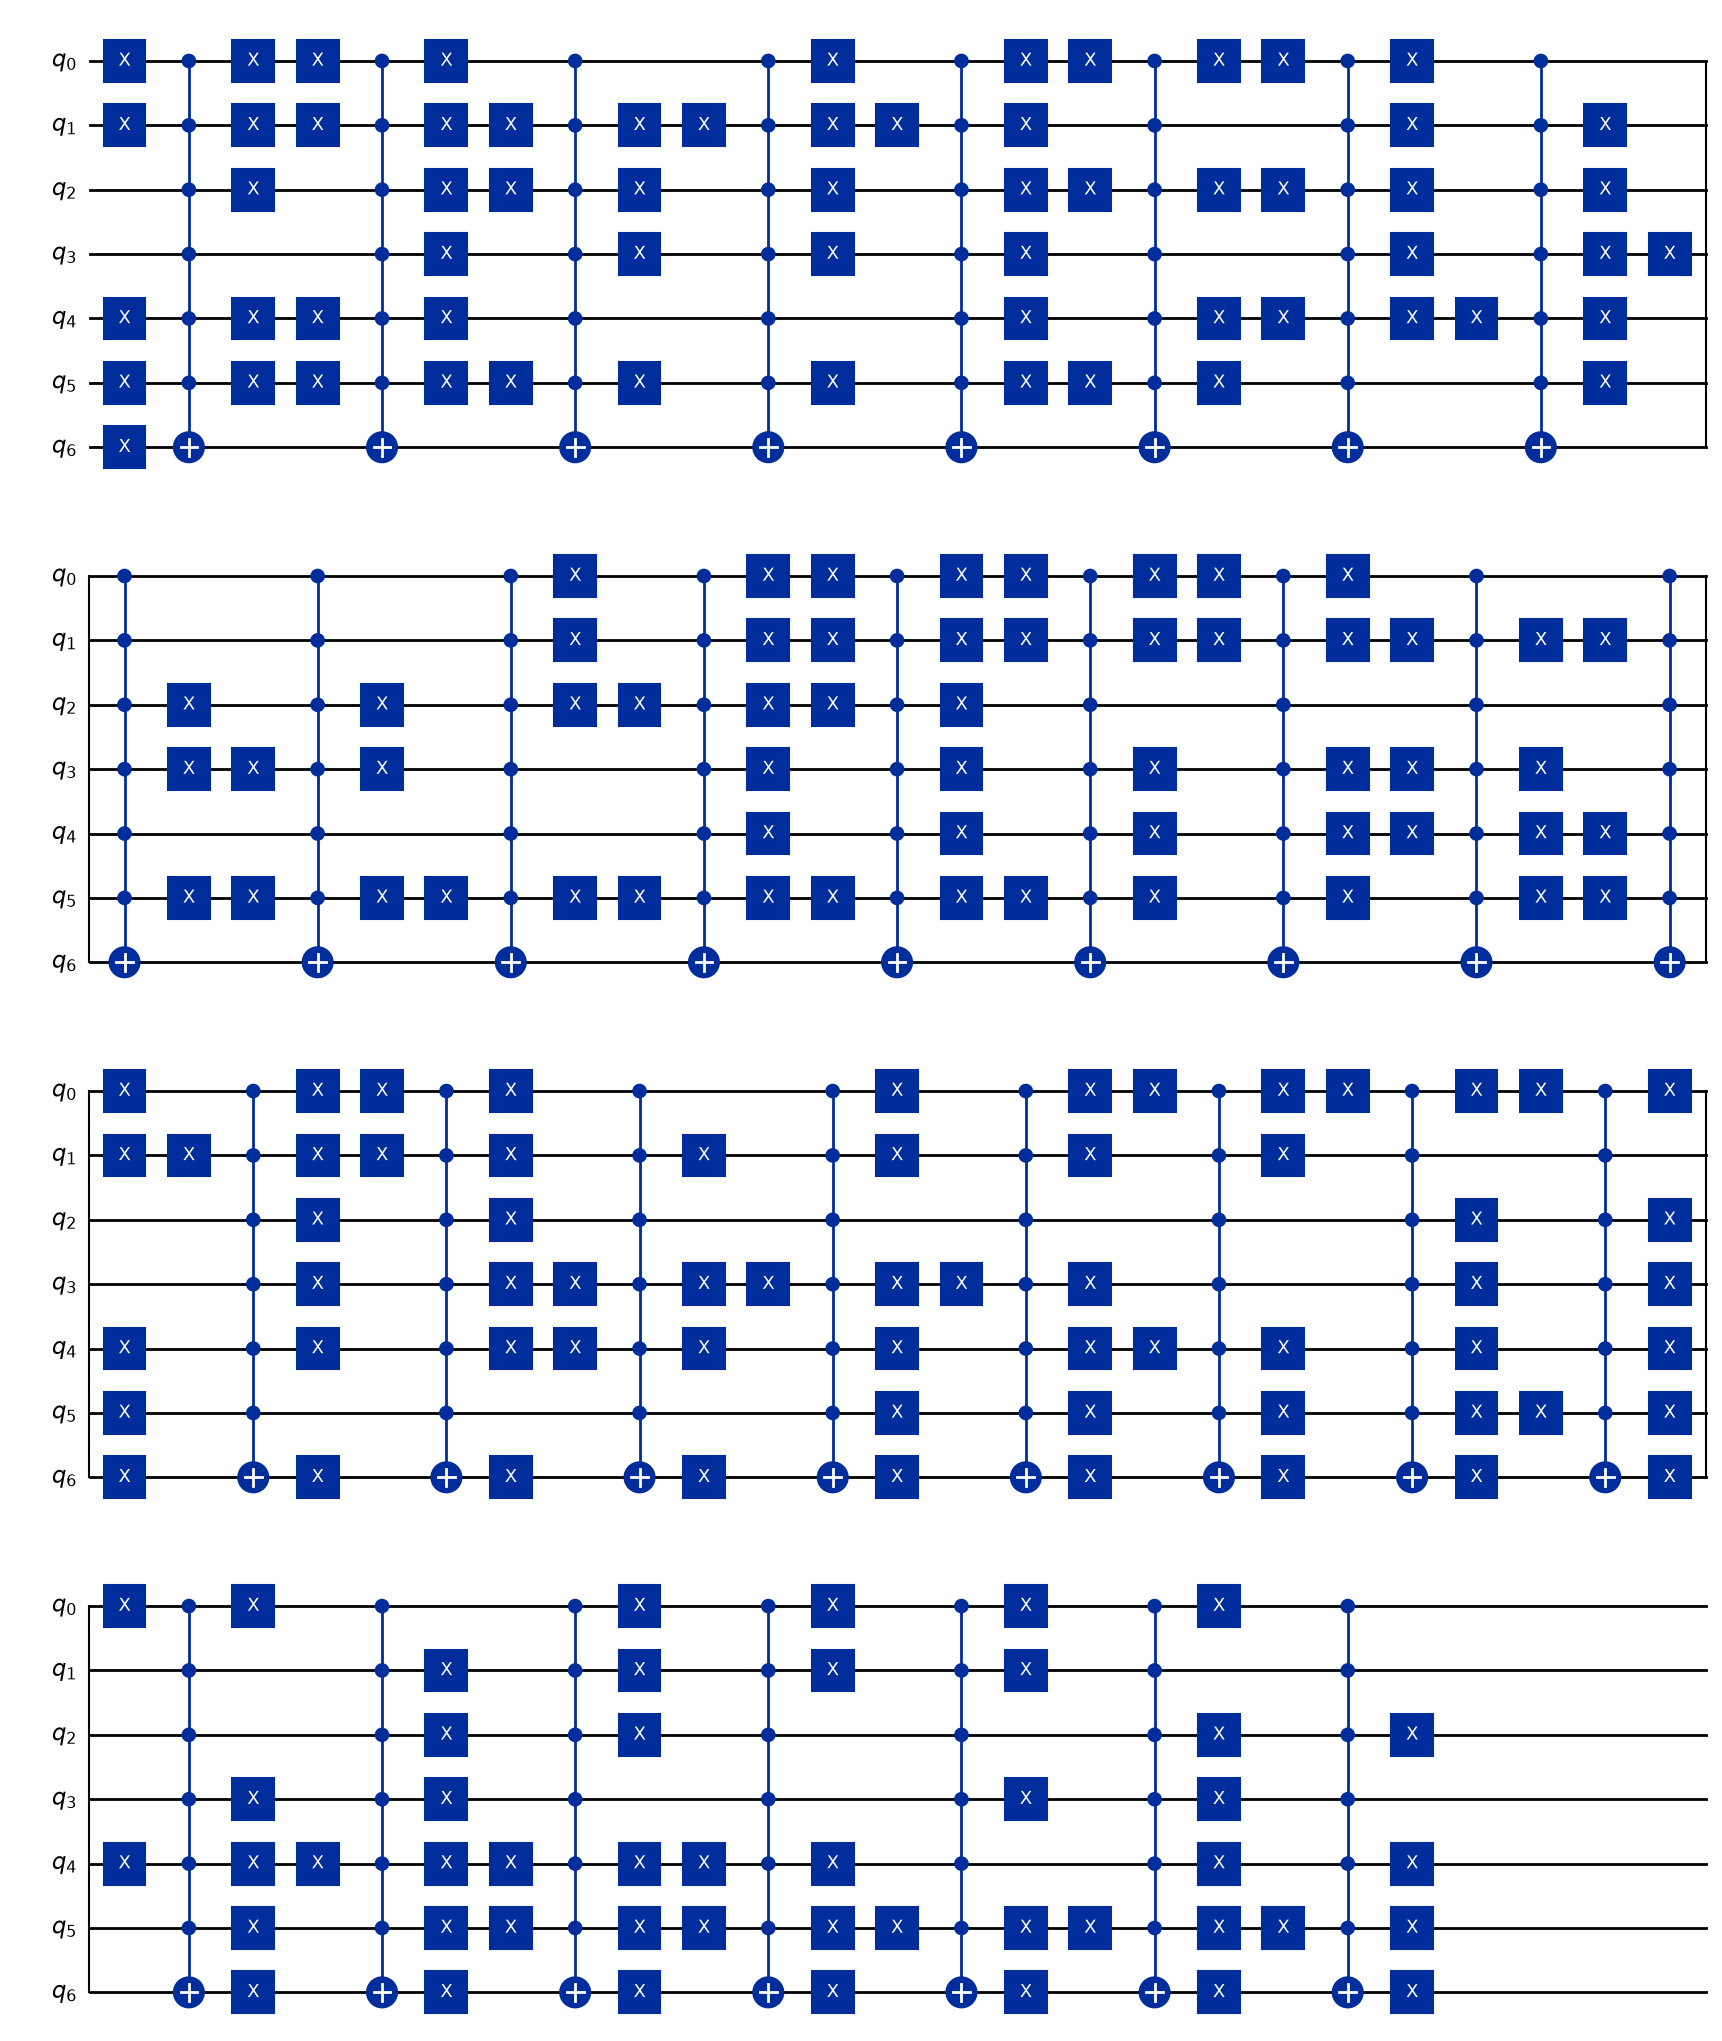

In [20]:
oraclenr = 1  # determines the oracle
N = 6
oracle = dj_problem_oracle(oraclenr, N)  # gives one out of many oracles
oracle.name = "DJ-Oracle"
dj_problem_oracle(oraclenr, N, False).draw(output='mpl')

This oracle has $N = 6$ input qubits $q_0 \dots q_5$; the last qubit $q_6$ is the output. Just as in Part 2, we can use it classically: prepare one input bit string, apply the oracle, and measure $q_6$.

Note: here `input_str[i]` sets qubit $q_i$, so the **leftmost** character is $q_0$ — the opposite of the order in which Qiskit prints bit strings.

f(000000) = 0
f(100000) = 1
f(111111) = 1


f(010010) = 1


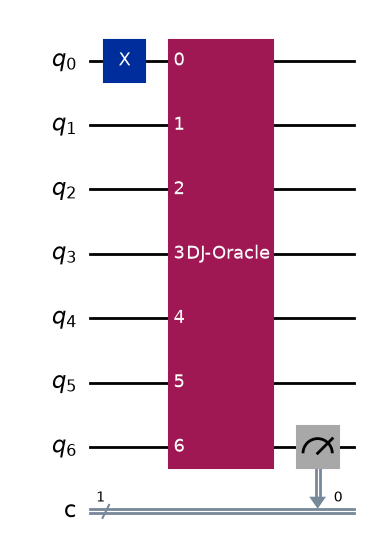

In [21]:
def dj_classical(oracle, n, input_str):
    """Query the oracle with ONE classical input string; the measured bit is f(input_str)."""
    qc = QuantumCircuit(n+1, 1)
    for i in range(n):              # input_str[i] -> qubit q_i
        if input_str[i] == '1':
            qc.x(i)
    qc.append(oracle, range(n+1))
    qc.measure(n, 0)                # measure the output qubit q_n
    return qc

for input_str in ['000000', '100000', '111111', '010010']:
    counts = run(dj_classical(oracle, N, input_str))
    print(f"f({input_str}) = {max(counts, key=counts.get)}")

dj_classical(oracle, N, '100000').draw(output='mpl')

**Q4.** From these four queries, are you *sure* whether oracle 1 is constant or balanced? In the worst case, how many queries could a classical computer need for this oracle (see Q2)?

**Answer:** Yes. The four queries give $f(000000)=0$ and $f(100000)=f(111111)=f(010010)=1$ (using the input order specified above). Since both output values occur, oracle 1 cannot be constant; under the promise it is balanced. In fact, the first two queries already establish this.

For an unknown promised function with six input bits, the classical worst-case bound is $2^{6-1}+1=33$ distinct queries. This is a general guarantee; these particular queries identify oracle 1 much earlier.

## Part 4) The Deutsch-Jozsa algorithm
Using a quantum computer, we can decide whether the oracle is constant or balanced with 100% confidence after only **one** call to the oracle $|x\rangle|y\rangle \mapsto |x\rangle|y \oplus f(x)\rangle$. The circuit is the Deutsch circuit from Part 2.3 with the single input qubit replaced by $n$ input qubits:

| | Deutsch (Part 2) | Deutsch-Jozsa |
|---|---|---|
| qubits | input $q_0$, output $q_1$ | inputs $q_0 \dots q_{n-1}$, output $q_n$ |
| $\lvert\psi_0\rangle$ | $\lvert-\rangle \otimes \lvert0\rangle$ | $\lvert-\rangle \otimes \lvert0\rangle^{\otimes n}$ |
| $\lvert\psi_1\rangle$ | H on $q_0$ | H on each of $q_0 \dots q_{n-1}$ |
| after the oracle | H on $q_0$, measure $q_0$ | H on each input, measure $q_0 \dots q_{n-1}$ |
| constant if | result is 0 | result is all 0 |

Remember that Qiskit writes states as $\vert b_n \dots b_1 b_0\rangle$, i.e. the last bit $b_0$ is the state of qubit $q_0$. So we want to initialise
$$\vert \psi_0 \rangle = \vert -\rangle \otimes \vert0\rangle^{\otimes n}.$$


<div class="alert alert-block alert-success">

**Exercise 4: Prepare $\vert \psi_0 \rangle$**

Complete <code>psi_0(n)</code> so that it builds $\vert \psi_0 \rangle = \vert -\rangle \otimes \vert0\rangle^{\otimes n}$: the state $|-\rangle$ on the output qubit $q_n$ and $|0\rangle$ on the input qubits $q_0 \dots q_{n-1}$.

Hint: this is the first step of <code>deutsch_circuit</code>, but the output qubit is now $q_n$.

</div>

In [22]:
n = N

def psi_0(n):
    qc = QuantumCircuit(n+1, n)
    # Inputs start in |0>; prepare the output in |-> = H X |0>.
    qc.x(n)
    qc.h(n)
    return qc

psi_0 is correct


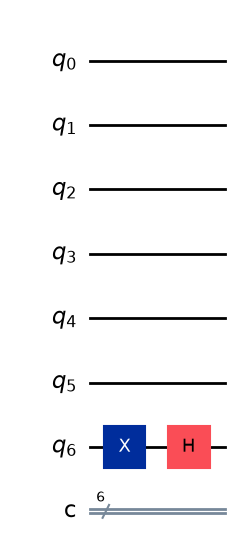

In [23]:
# Check
check_psi_0(psi_0, n)
psi_0(n).draw(output='mpl')

Next, put the inputs into an equal superposition:
$$\vert \psi_1 \rangle = \vert -\rangle \otimes \frac{1}{\sqrt{2^n}}\sum_{x=0}^{2^n-1} \vert x\rangle$$


<div class="alert alert-block alert-success">

**Exercise 5: Create the superposition $\vert \psi_1 \rangle$**

Complete <code>psi_1(n)</code>: start from <code>psi_0(n)</code>, then put every input qubit $q_0 \dots q_{n-1}$ into superposition.

Hint: <code>qc.h()</code> also accepts a list or a <code>range</code> of qubits.

</div>

In [24]:
def psi_1(n):
    qc = psi_0(n)
    qc.h(range(n))
    return qc

psi_1 is correct


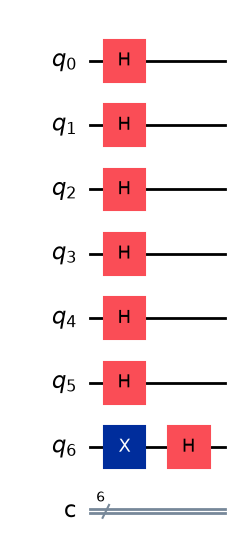

In [25]:
# Check
check_psi_1(psi_1, n)
psi_1(n).draw(output='mpl')

Apply the oracle **once**. By phase kickback (Part 2.2) this gives
$$\vert \psi_2 \rangle = \vert -\rangle \otimes \frac{1}{\sqrt{2^{n}}}\sum_{x=0}^{2^n-1}(-1)^{f(x)}\vert x\rangle$$


<div class="alert alert-block alert-success">

**Exercise 6: Apply the oracle to get $\vert \psi_2 \rangle$**

Complete <code>psi_2(oracle, n)</code>: start from <code>psi_1(n)</code> and apply the oracle <b>once</b>. The oracle is a gate that acts on all $n+1$ qubits.

Hint: a gate is added to a circuit with <code>qc.append(gate, qubits)</code>.

</div>

In [26]:
def psi_2(oracle, n):
    qc = psi_1(n)
    qc.append(oracle, range(n+1))  # Exactly one oracle query.
    return qc

psi_2 is correct


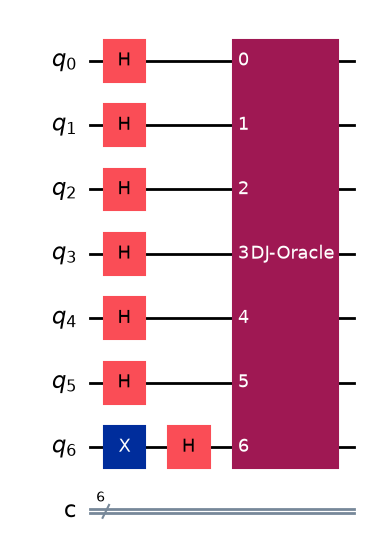

In [27]:
# Check
check_psi_2(psi_2, oracle, n)
psi_2(oracle, n).draw(output='mpl')

Finally, we ignore the output qubit $q_n$, apply a Hadamard to each input qubit and measure the inputs.


<div class="alert alert-block alert-success">

**Exercise 7: Complete the Deutsch-Jozsa circuit**

Complete <code>full_circuit(oracle, n)</code>: start from <code>psi_2(oracle, n)</code>, apply a Hadamard to every input qubit, then measure every input qubit $q_i$ into classical bit $i$. The output qubit $q_n$ is not measured.

</div>

In [28]:
def full_circuit(oracle, n):
    qc = psi_2(oracle, n)
    qc.h(range(n))
    qc.measure(range(n), range(n))
    return qc

full_circuit is correct


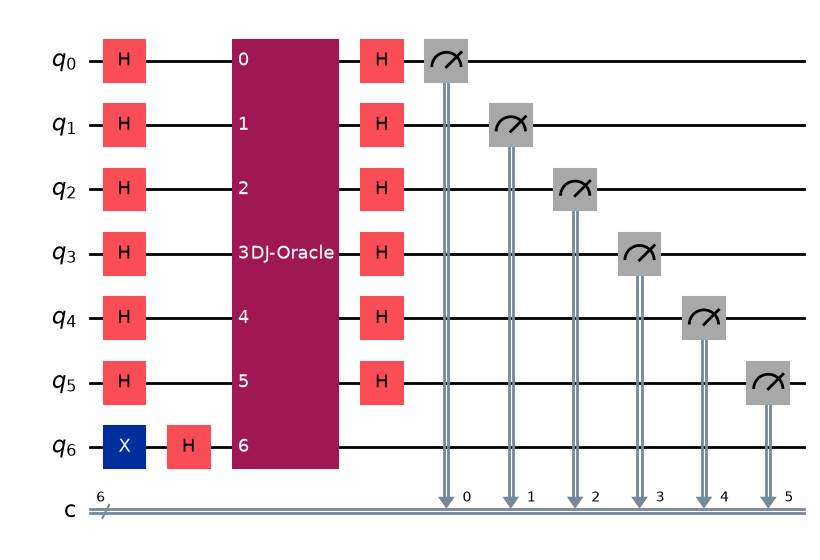

In [29]:
# Check
check_full_circuit(full_circuit, n)
dj_circuit = full_circuit(oracle, n)
dj_circuit.draw(output='mpl')

For 6 input qubits the circuit should look like this:

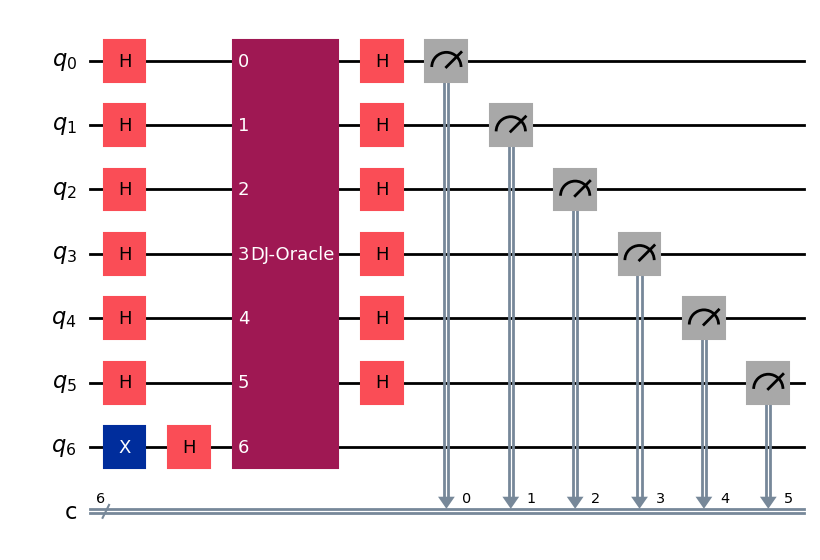

As shown in the lecture, the probability of measuring $|0\rangle^{\otimes n}$ is
$$
\left| \frac{1}{2^n}\sum_{x=0}^{2^n-1}(-1)^{f(x)} \right|^2 = \begin{cases} 1 & \text{if } f \text{ is constant} \\ 0 & \text{if } f \text{ is balanced} \end{cases}
$$
so **all zeros → constant, anything else → balanced**. (The full derivation is in the appendix at the end.)

Let us run the circuit on the simulator:

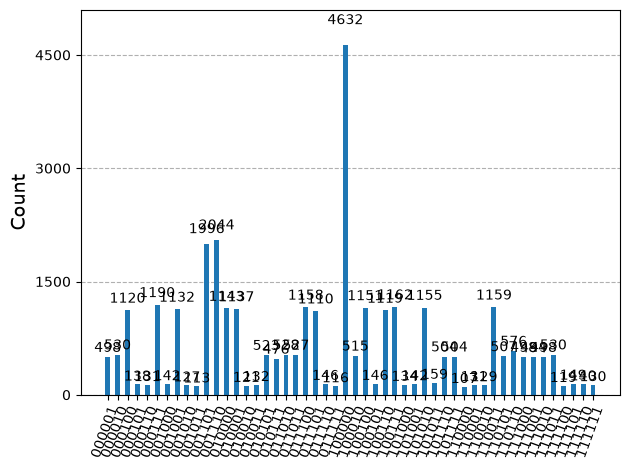

In [30]:
answer = run(dj_circuit, shots=1 << 15)
plot_histogram(answer)

## Problems 1–10
The cell below runs the Deutsch-Jozsa circuit on oracles 1–10. In principle **one shot (one query)** per oracle is enough; we use 1024 shots only to show that the classification is always the same. A balanced oracle may produce several different nonzero bit strings.

Remember that every oracle is guaranteed to be either constant or balanced, so there is no third case to consider. Decide for each oracle which one it is from the measurement result of the first register, and fill in the table.

In [31]:
problem_results = {}
for problem in range(1, 11):
    problem_oracle = dj_problem_oracle(problem, N)
    counts = run(full_circuit(problem_oracle, N))
    p_zero = counts.get('0' * N, 0) / sum(counts.values())
    kind = 'constant' if p_zero == 1 else 'balanced'
    problem_results[problem] = kind
    print(f"Problem {problem:2d}: P(|{'0' * N}>) = {p_zero:.2f} -> {kind}; "
          f"most frequent outcome: {max(counts, key=counts.get)}")

Problem  1: P(|000000>) = 0.00 -> balanced; most frequent outcome: 100000
Problem  2: P(|000000>) = 1.00 -> constant; most frequent outcome: 000000


Problem  3: P(|000000>) = 1.00 -> constant; most frequent outcome: 000000
Problem  4: P(|000000>) = 1.00 -> constant; most frequent outcome: 000000


Problem  5: P(|000000>) = 1.00 -> constant; most frequent outcome: 000000
Problem  6: P(|000000>) = 0.00 -> balanced; most frequent outcome: 101001
Problem  7: P(|000000>) = 0.00 -> balanced; most frequent outcome: 000010


Problem  8: P(|000000>) = 0.00 -> balanced; most frequent outcome: 100110
Problem  9: P(|000000>) = 0.00 -> balanced; most frequent outcome: 101110


Problem 10: P(|000000>) = 1.00 -> constant; most frequent outcome: 000000


| Problem | constant or balanced? |
|---|---|
| 1 | balanced |
| 2 | constant |
| 3 | constant |
| 4 | constant |
| 5 | constant |
| 6 | balanced |
| 7 | balanced |
| 8 | balanced |
| 9 | balanced |
| 10 | constant |

The simulator gives $P(000000)=1$ for problems 2, 3, 4, 5, and 10, and $P(000000)=0$ for problems 1, 6, 7, 8, and 9. Under the promise, a single ideal shot suffices: all zeros means constant and any nonzero string means balanced. The repeated shots above illustrate these probabilities; they are separate executions, each using one oracle call.

## Appendix: why does it work? (reading)
Consider that for any state $|x\rangle = |x_{n-1} \ldots x_0\rangle = |x_{n-1}\rangle \otimes \ldots \otimes |x_0\rangle$, applying a Hadamard gate to each qubit yields the state:
$$
\begin{aligned}
H^{\otimes n} |x\rangle &= H|x_{n-1}\rangle \otimes \ldots \otimes H|x_0\rangle \\
&= \frac{1}{\sqrt{2^n}} \sum_{y=0}^{2^n-1} (-1)^{x \cdot y} |y\rangle,
\end{aligned}
$$
where $x \cdot y = x_0y_0 + x_1y_1 + \ldots + x_{n-1}y_{n-1}$ is the sum of the bitwise product.

At this point the output qubit may be ignored. Applying a Hadamard gate to each qubit in the input register yields the state:
$$
\begin{aligned}
    \lvert \psi_3 \rangle
        & = \frac{1}{2^n}\sum_{x=0}^{2^n-1}(-1)^{f(x)}
            \left[ \sum_{y=0}^{2^n-1}(-1)^{x \cdot y}
            \vert y \rangle \right] \\
        & = \frac{1}{2^n}\sum_{y=0}^{2^n-1}
            \left[ \sum_{x=0}^{2^n-1}(-1)^{f(x)+x \cdot y} \right]
            \vert y \rangle,
\end{aligned}
$$

Now, consider the amplitude of the basis state $|0\rangle^{\otimes n} = |0 \ldots 0\rangle$ in this final state $\vert \psi_3 \rangle$. This amplitude is given by
$$
\frac{1}{2^n}\sum_{x=0}^{2^n-1}(-1)^{f(x)+x \cdot 0} = \frac{1}{2^n}\sum_{x=0}^{2^n-1}(-1)^{f(x)}.
$$
yielding the probability of measuring the state $|0\rangle^{\otimes n}$ as
$$
\left| \frac{1}{2^n}\sum_{x=0}^{2^n-1}(-1)^{f(x)} \right|^2 = \begin{cases} 1 & \text{if } f \text{ is constant} \\ 0 & \text{if } f \text{ is balanced} \end{cases}
$$
In the balanced case the $(-1)^{f(x)}$ terms cancel and the probability of measuring $|0\rangle^{\otimes n}$ is $0$. In the constant case $(-1)^{f(x)}$ is the same ($+1$ or $-1$) for all $x$, so the probability is $1$.